<a href="https://colab.research.google.com/github/AlbertP97/Med-VQA-Survey/blob/main/SLAKE.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# SLAKE Dataset Analysis

This notebook analyzes the SLAKE English dataset for the doctoral research project (Paper 2).

## Dataset Overview
SLAKE is a dataset of medical visual question answering focusing on radiology images.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import json
from pathlib import Path
import nltk
from nltk.tokenize import word_tokenize

# Download the required NLTK data
nltk.download('punkt', quiet=True)

# Visualization configuration
sns.set_style("whitegrid")
plt.rcParams['figure.figsize'] = (12, 6)

## 1. Import Libraries

In [2]:
from google.colab import files
import json
import pandas as pd

# Select and upload the file from the computer
uploaded_files = files.upload()

# Get the uploaded file name
file_name = next(iter(uploaded_files))

# Read the JSON file
json_data = json.loads(uploaded_files[file_name].decode('utf-8'))

# Convert it to a DataFrame
df = pd.DataFrame(json_data)

print(f"Dataset loaded successfully")
print(f"Number of records: {len(df)}")
print(f"Number of columns: {len(df.columns)}")

Saving SLAKE_EN.json to SLAKE_EN.json
Dataset loaded successfully
Number of records: 7033
Number of columns: 12



Data preparation complete.
Average words per question: 8.03
Median words per question: 8.00
Average words per answer: 1.40
Median words per answer: 1.00


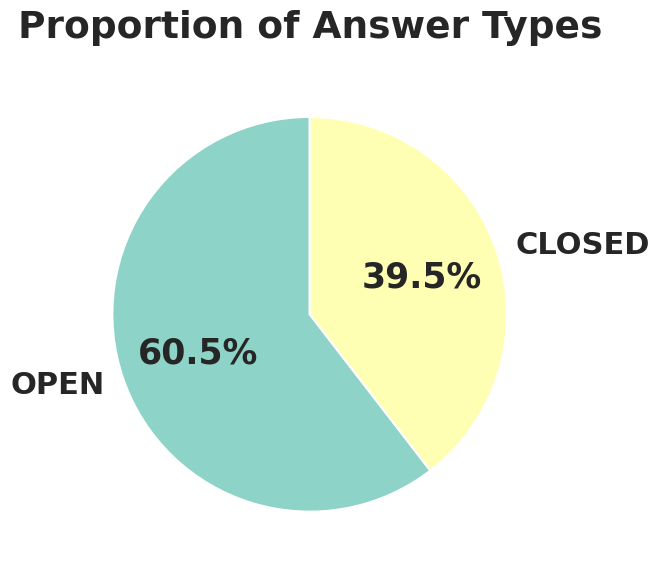

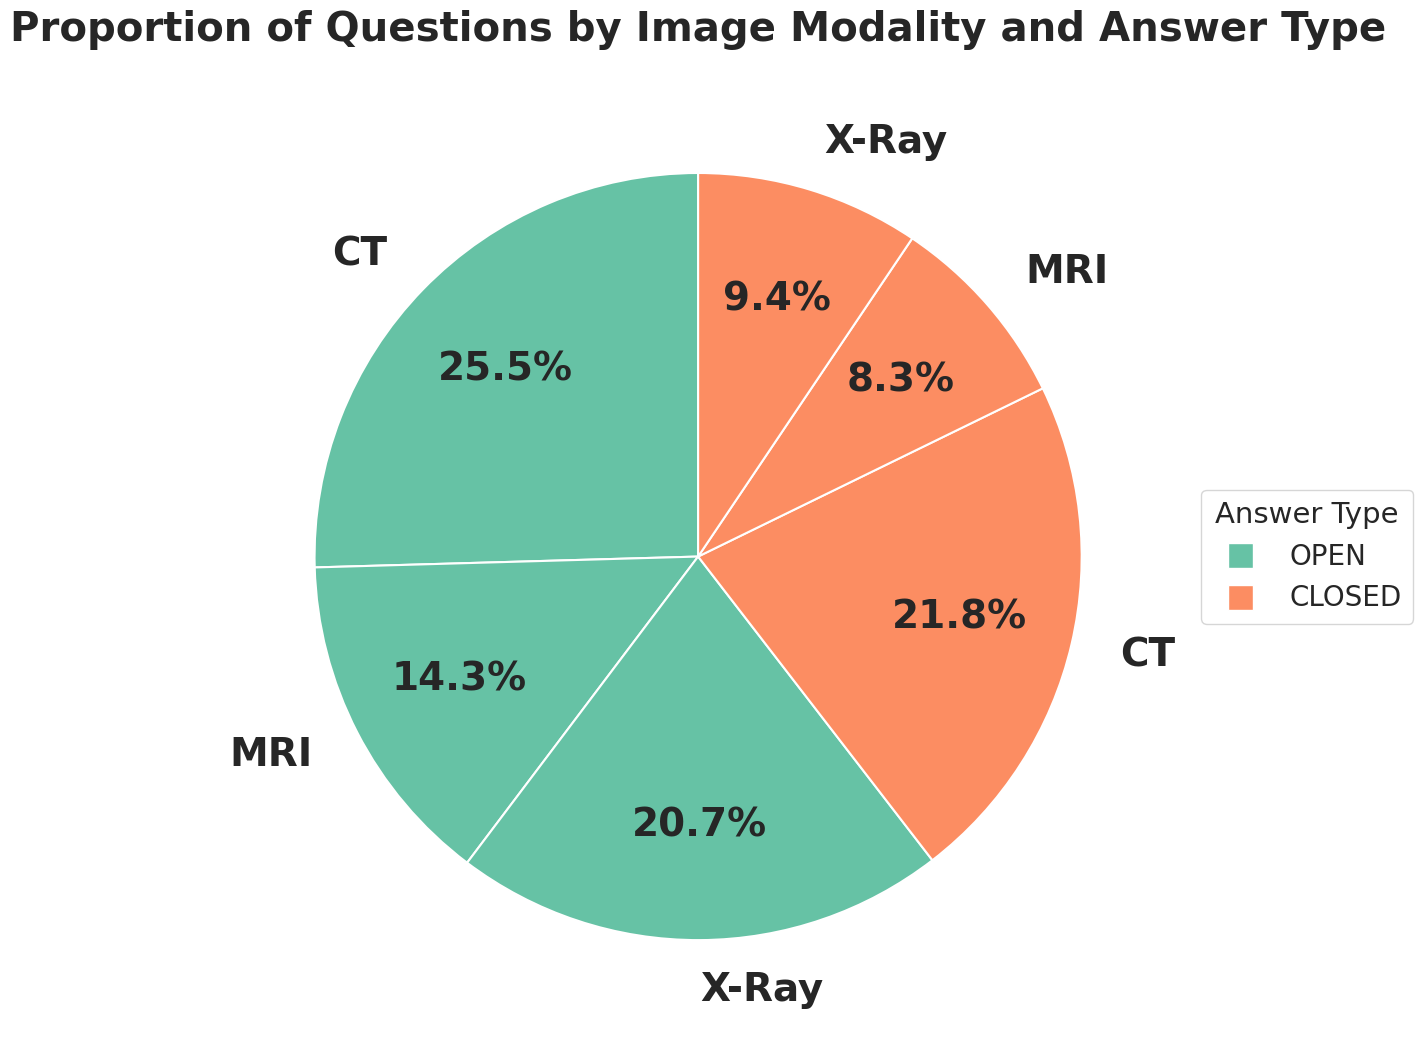

In [4]:
from matplotlib.lines import Line2D

# ============================================================
# 2. GENERAL CONFIGURETION
# ============================================================

sns.set_style("whitegrid")

plt.rcParams.update({
    'font.family': 'sans-serif',
    'font.size': 16,
    'axes.titlesize': 23,
    'axes.titleweight': 'bold',
    'axes.labelsize': 19,
    'xtick.labelsize': 15,
    'ytick.labelsize': 15,
    'legend.fontsize': 15,
    'legend.title_fontsize': 16,
    'figure.titlesize': 24
})


# ============================================================
# 3. CLEAN AND PREPARE THE DATA
# ============================================================

text_columns = [
    'question',
    'answer',
    'q_lang',
    'location',
    'modality',
    'answer_type',
    'base_type',
    'content_type'
]

for column in text_columns:
    df[column] = (
        df[column]
        .fillna('Unknown')
        .astype(str)
        .str.strip()
    )

# Standardize categories
df['answer_type'] = df['answer_type'].str.upper()

df['modality'] = df['modality'].replace({
    'ct': 'CT',
    'Ct': 'CT',
    'mri': 'MRI',
    'Mri': 'MRI',
    'xray': 'X-Ray',
    'Xray': 'X-Ray',
    'x-ray': 'X-Ray'
})

# Calculate word counts
df['question_words'] = df['question'].str.split().str.len()
df['answer_words'] = df['answer'].str.split().str.len()

print("\nData preparation complete.")
print(
    f"Average words per question: "
    f"{df['question_words'].mean():.2f}"
)
print(
    f"Median words per question: "
    f"{df['question_words'].median():.2f}"
)
print(
    f"Average words per answer: "
    f"{df['answer_words'].mean():.2f}"
)
print(
    f"Median words per answer: "
    f"{df['answer_words'].median():.2f}"
)

# ============================================================
# FIGURE 1
# PROPORTION OF ANSWER TYPES
# ============================================================

answer_order = ['OPEN', 'CLOSED']

answer_types_dist = (
    df['answer_type']
    .value_counts()
    .reindex(answer_order)
    .dropna()
)

fig, ax = plt.subplots(figsize=(7, 6))

answer_colors = {
    'OPEN': '#8dd3c7',
    'CLOSED': '#ffffb3'
}

wedges, texts, percentages = ax.pie(
    answer_types_dist.values,
    labels=answer_types_dist.index,
    autopct='%1.1f%%',
    startangle=90,
    colors=[
        answer_colors[answer_type]
        for answer_type in answer_types_dist.index
    ],
    textprops={
        'fontsize': 22,
        'fontweight': 'bold'
    },
    wedgeprops={
        'edgecolor': 'white',
        'linewidth': 1.5
    }
)

# Specific size for the OPEN and CLOSED labels
for text in texts:
    text.set_fontsize(22)
    text.set_fontweight('bold')

# Specific size for the percentages
for percentage in percentages:
    percentage.set_fontsize(25)
    percentage.set_fontweight('bold')

ax.set_title(
    'Proportion of Answer Types',
    fontsize=27,
    fontweight='bold',
    pad=22
)

plt.tight_layout()
plt.show()


# ============================================================
# FIGURE 2
# PROPORTION BY MODALITY AND ANSWER TYPE
# ============================================================

modality_answer_df = (
    df.groupby(['answer_type', 'modality'])
    .size()
    .reset_index(name='count')
)

type_order = {
    'OPEN': 0,
    'CLOSED': 1
}

modality_order = {
    'CT': 0,
    'MRI': 1,
    'X-Ray': 2
}

modality_answer_df['answer_order'] = (
    modality_answer_df['answer_type']
    .map(type_order)
)

modality_answer_df['modality_order'] = (
    modality_answer_df['modality']
    .map(modality_order)
)

modality_answer_df = modality_answer_df.sort_values(
    ['answer_order', 'modality_order']
)

values = modality_answer_df['count'].to_numpy()
modalities = modality_answer_df['modality'].tolist()
answer_types = modality_answer_df['answer_type'].tolist()

type_colors = {
    'OPEN': '#66c2a5',
    'CLOSED': '#fc8d62'
}

segment_colors = [
    type_colors[answer_type]
    for answer_type in answer_types
]

fig, ax = plt.subplots(figsize=(12, 11))

wedges, texts, percentages = ax.pie(
    values,
    labels=modalities,
    autopct=lambda percentage: (
        f'{percentage:.1f}%'
        if percentage >= 2 else ''
    ),
    startangle=90,
    labeldistance=1.13,
    pctdistance=0.70,
    colors=segment_colors,
    textprops={
        'fontsize': 25,
        'fontweight': 'bold'
    },
    wedgeprops={
        'edgecolor': 'white',
        'linewidth': 1.5
    }
)

# Size of the CT, MRI, and X-Ray labels
for text in texts:
    text.set_fontsize(28)
    text.set_fontweight('bold')

# Percentage size
for percentage in percentages:
    percentage.set_fontsize(28)
    percentage.set_fontweight('bold')

legend_elements = [
    Line2D(
        [0],
        [0],
        marker='s',
        linestyle='',
        color='white',
        markerfacecolor=type_colors['OPEN'],
        markersize=18,
        label='OPEN'
    ),
    Line2D(
        [0],
        [0],
        marker='s',
        linestyle='',
        color='white',
        markerfacecolor=type_colors['CLOSED'],
        markersize=18,
        label='CLOSED'
    )
]

ax.legend(
    handles=legend_elements,
    title='Answer Type',
    loc='center left',
    bbox_to_anchor=(1.01, 0.5),
    fontsize=20,
    title_fontsize=21
)

ax.set_title(
    'Proportion of Questions by Image Modality and Answer Type',
    fontsize=29,
    fontweight='bold',
    pad=26
)

plt.tight_layout()
plt.show()



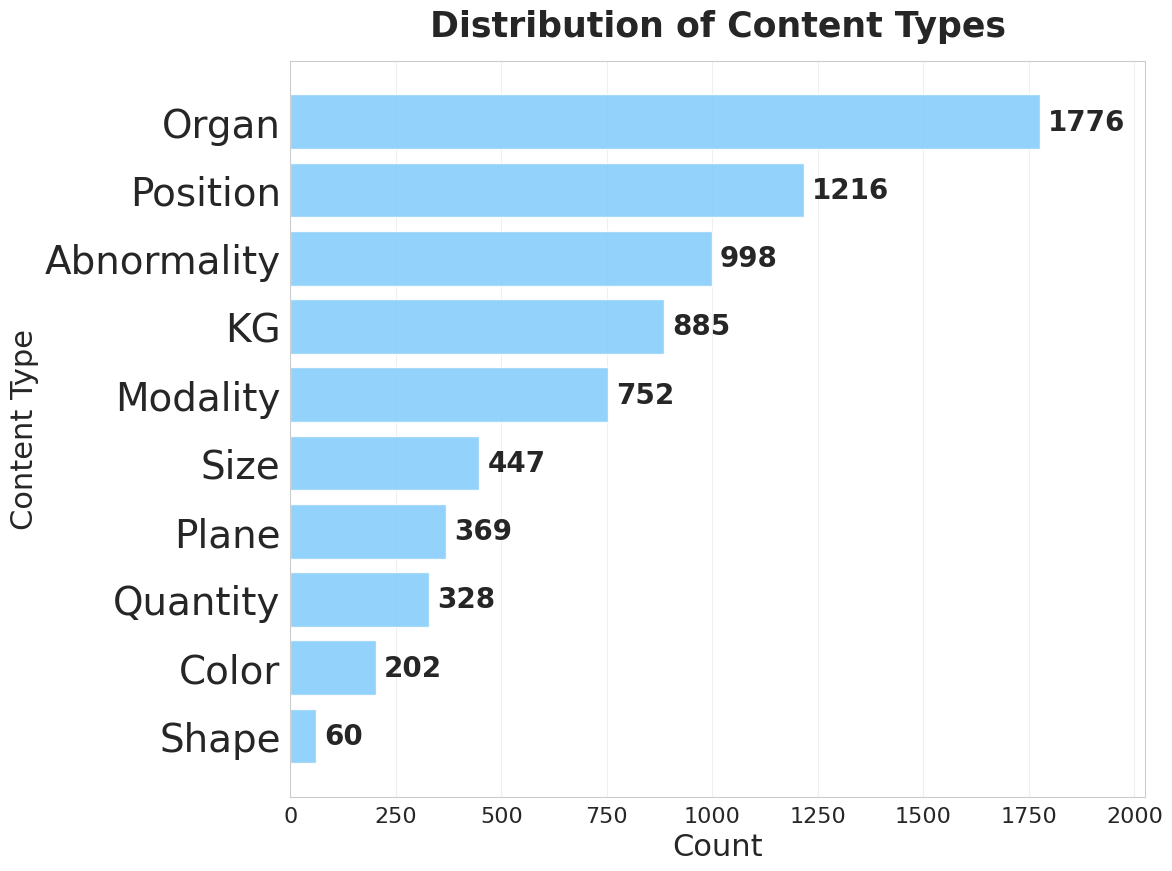

In [5]:


# ============================================================
# FIGURE 3
# DISTRIBUTION OF CONTENT TYPES
# ============================================================

content_types_dist = (
    df['content_type']
    .value_counts()
    .sort_values()
)

fig, ax = plt.subplots(figsize=(12, 9))

bars = ax.barh(
    content_types_dist.index,
    content_types_dist.values,
    color='lightskyblue',
    alpha=0.9
)

ax.set_title(
    'Distribution of Content Types',
    fontsize=25,
    fontweight='bold',
    pad=18
)

ax.set_xlabel('Count', fontsize=22)
ax.set_ylabel('Content Type', fontsize=22)

ax.tick_params(axis='x', labelsize=16)
ax.tick_params(axis='y', labelsize=28)

ax.bar_label(
    bars,
    padding=6,
    fontsize=20,
    fontweight='bold'
)

ax.set_xlim(
    0,
    content_types_dist.max() * 1.14
)

ax.grid(axis='x', alpha=0.3)
ax.grid(axis='y', visible=False)

plt.tight_layout()
plt.show()


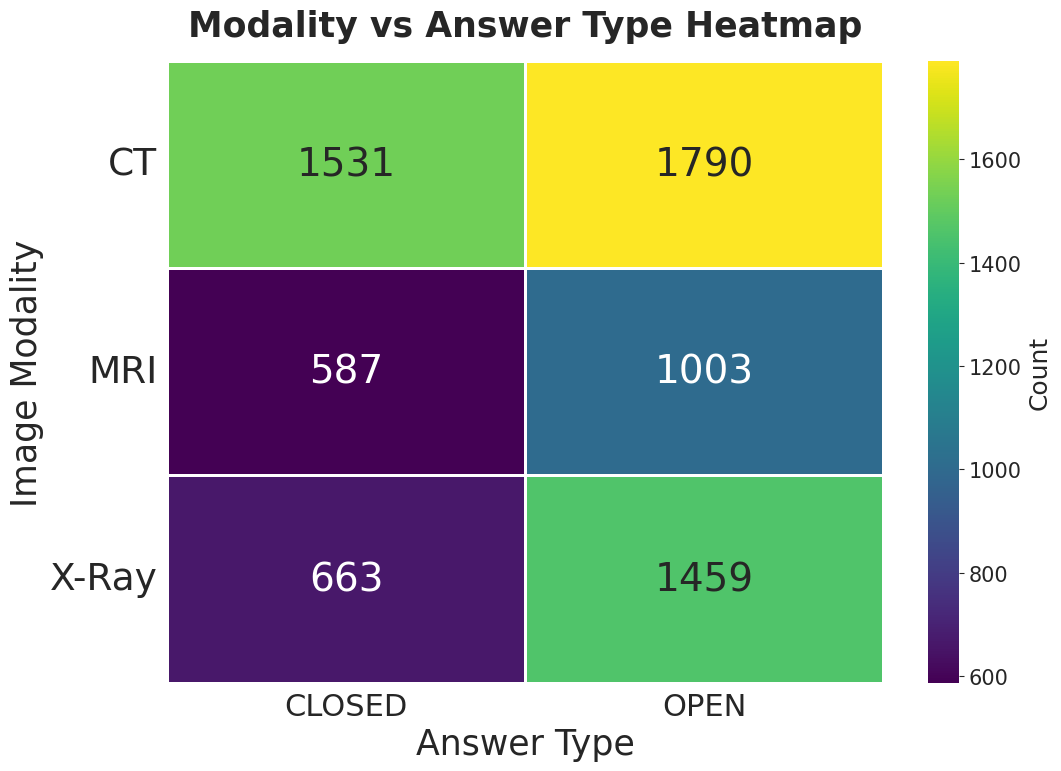

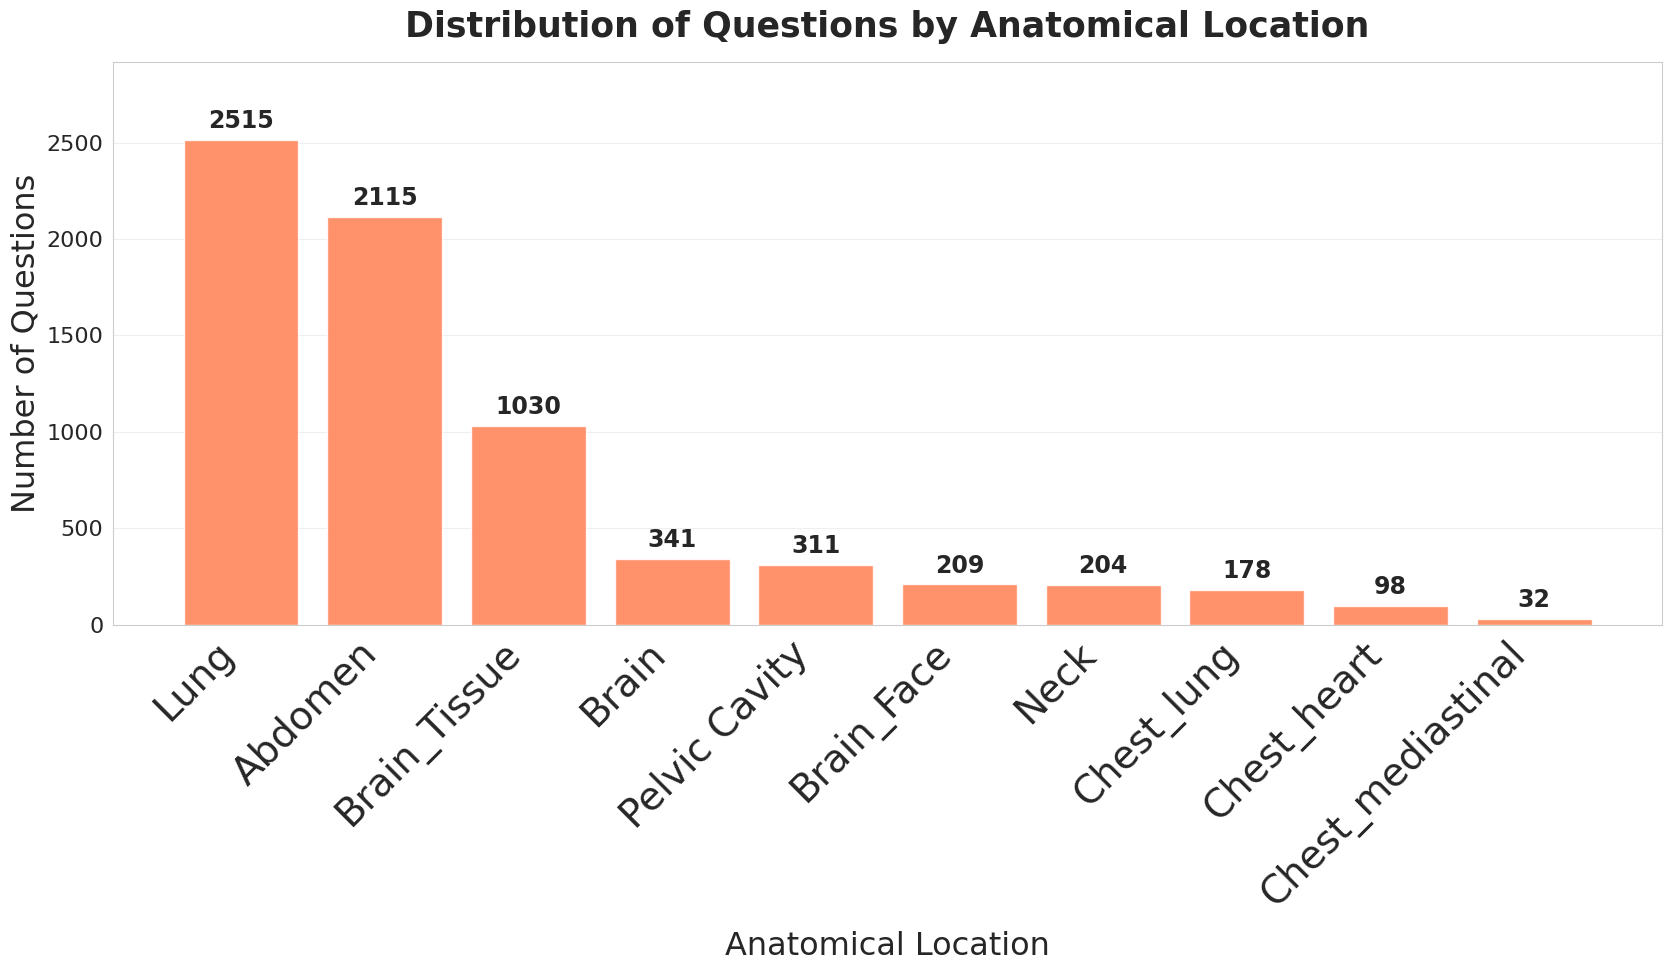

In [6]:


# ============================================================
# FIGURE 4
# HEATMAP OF MODALITY AND ANSWER TYPE
# ============================================================

modality_anstype_cross = pd.crosstab(
    df['modality'],
    df['answer_type']
)

# Reorder rows and columns
modality_anstype_cross = modality_anstype_cross.reindex(
    index=['CT', 'MRI', 'X-Ray'],
    columns=['CLOSED', 'OPEN'],
    fill_value=0
)

fig, ax = plt.subplots(figsize=(11, 8))

sns.heatmap(
    modality_anstype_cross,
    annot=True,
    fmt='d',
    cmap='viridis',
    linewidths=1,
    linecolor='white',
    annot_kws={
        'size': 28
    },
    cbar_kws={
        'label': 'Count'
    },
    ax=ax
)

ax.set_title(
    'Modality vs Answer Type Heatmap',
    fontsize=25,
    fontweight='bold',
    pad=18
)

ax.set_xlabel('Answer Type', fontsize=25)
ax.set_ylabel('Image Modality', fontsize=25)

ax.tick_params(
    axis='x',
    labelsize=22,
    rotation=0
)

ax.tick_params(
    axis='y',
    labelsize=27,
    rotation=0
)

colorbar = ax.collections[0].colorbar
colorbar.ax.tick_params(labelsize=15)
colorbar.set_label('Count', fontsize=18)

plt.tight_layout()
plt.show()


# ============================================================
# FIGURE 5
# DISTRIBUTION BY ANATOMICAL LOCATION
# ============================================================

location_counts = df['location'].value_counts()

fig, ax = plt.subplots(figsize=(17, 10))

bars = ax.bar(
    location_counts.index,
    location_counts.values,
    color='coral',
    alpha=0.85
)

ax.set_title(
    'Distribution of Questions by Anatomical Location',
    fontsize=25,
    fontweight='bold',
    pad=18
)

ax.set_xlabel(
    'Anatomical Location',
    fontsize=23,
    labelpad=12
)

ax.set_ylabel(
    'Number of Questions',
    fontsize=23
)

ax.tick_params(
    axis='y',
    labelsize=16
)

ax.tick_params(
    axis='x',
    labelsize=28,
    rotation=45
)

for label in ax.get_xticklabels():
    label.set_horizontalalignment('right')

ax.bar_label(
    bars,
    padding=5,
    fontsize=17,
    fontweight='bold'
)

ax.set_ylim(
    0,
    location_counts.max() * 1.16
)

ax.grid(axis='y', alpha=0.3)
ax.grid(axis='x', visible=False)

plt.tight_layout()
plt.show()



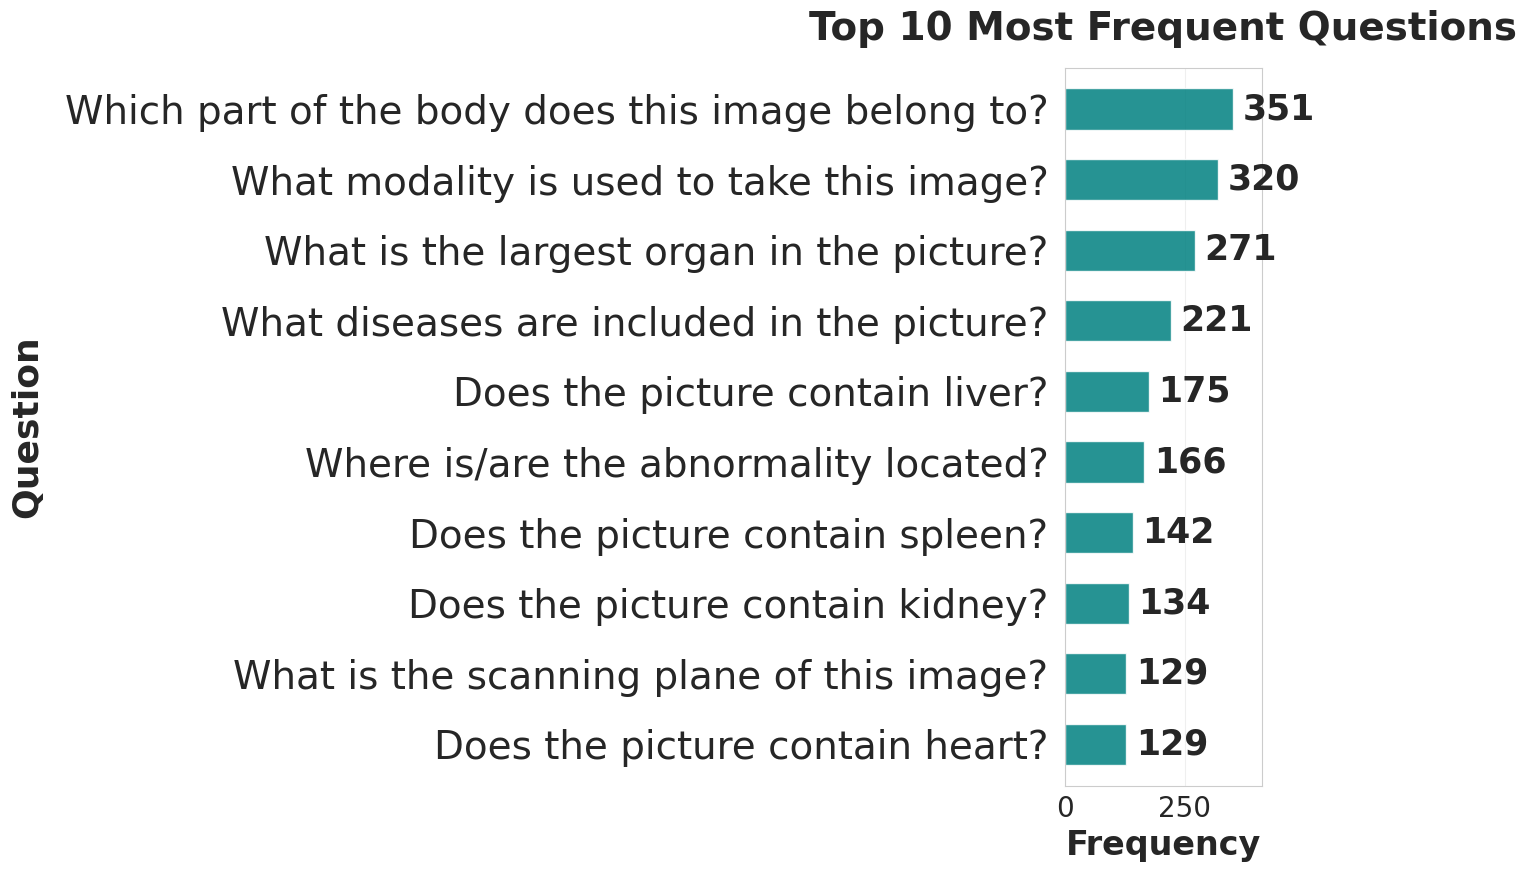

In [7]:
# ============================================================
# FIGURE 6
# TOP 10 MOST FREQUENT QUESTIONS
# Narrow bars with reduced spacing
# ============================================================

top_questions = (
    df['question']
    .value_counts()
    .head(10)
    .sort_values()
)

question_labels = [
    question if len(question) <= 75
    else question[:72] + '...'
    for question in top_questions.index
]

# Positions with reduced spacing
spacing = 0.65
positions = np.arange(len(top_questions)) * spacing

fig, ax = plt.subplots(figsize=(13, 9))

bars = ax.barh(
    positions,
    top_questions.values,
    height=0.38,
    color='teal',
    alpha=0.85
)

# Place questions at the custom positions
ax.set_yticks(positions)
ax.set_yticklabels(
    question_labels,
    fontsize=28
)

ax.set_title(
    'Top 10 Most Frequent Questions',
    fontsize=28,
    fontweight='bold',
    pad=20
)

ax.set_xlabel(
    'Frequency',
    fontsize=24,
    fontweight='bold'
)

ax.set_ylabel(
    'Question',
    fontsize=26,
    fontweight='bold',
    labelpad=15
)

ax.tick_params(
    axis='x',
    labelsize=20
)

ax.tick_params(
    axis='y',
    pad=8
)

ax.bar_label(
    bars,
    padding=7,
    fontsize=25,
    fontweight='bold'
)

ax.set_xlim(
    0,
    top_questions.max() * 1.17
)

# Reduce extra space above and below
ax.set_ylim(
    positions[0] - 0.38,
    positions[-1] + 0.38
)

ax.grid(axis='x', alpha=0.3)
ax.grid(axis='y', visible=False)

plt.tight_layout()
plt.show()



In [8]:
# Positions with reduced spacing
spacing = 0.65
positions = np.arange(len(top_answers)) * spacing

# Two X-axis segments to produce one break
fig, (ax1, ax2) = plt.subplots(
    1, 2,
    sharey=True,
    figsize=(13, 8),
    gridspec_kw={
        'width_ratios': [3.4, 1.6],
        'wspace': 0.04
    }
)

axes = (ax1, ax2)

# Draw the bars in both segments
for ax in axes:
    ax.barh(
        positions,
        top_answers.values,
        height=0.38,
        color='darkorange',
        alpha=0.85
    )

    ax.grid(
        axis='x',
        alpha=0.3
    )

    ax.grid(
        axis='y',
        visible=False
    )

    ax.set_axisbelow(True)

    ax.tick_params(
        axis='x',
        labelsize=20
    )

# Segment limits
ax1.set_xlim(0, 400)
ax2.set_xlim(1120, 1300)

# X-axis ticks
ax1.set_xticks([0, 100, 200, 300, 400])
ax2.set_xticks([1150, 1200, 1250])

# Y-axis labels
ax1.set_yticks(positions)

ax1.set_yticklabels(
    top_answers.index,
    fontsize=28
)

ax1.tick_params(
    axis='y',
    pad=8
)

# Hide repeated labels on the second axis
ax2.tick_params(
    axis='y',
    left=False,
    labelleft=False
)

# Y-axis label
ax1.set_ylabel(
    'Answer',
    fontsize=26,
    fontweight='bold',
    labelpad=15
)

# Keep little vertical space
ax1.set_ylim(
    positions[0] - 0.38,
    positions[-1] + 0.38
)

# Hide the interior borders
ax1.spines['right'].set_visible(False)
ax2.spines['left'].set_visible(False)

# Diagonal break marks
d = 0.012

kwargs = dict(
    color='black',
    clip_on=False,
    linewidth=1.5
)

# Right side of the first axis
ax1.plot(
    (1 - d, 1 + d),
    (-d, +d),
    transform=ax1.transAxes,
    **kwargs
)

ax1.plot(
    (1 - d, 1 + d),
    (1 - d, 1 + d),
    transform=ax1.transAxes,
    **kwargs
)

# Left side of the second axis
ax2.plot(
    (-d, +d),
    (-d, +d),
    transform=ax2.transAxes,
    **kwargs
)

ax2.plot(
    (-d, +d),
    (1 - d, 1 + d),
    transform=ax2.transAxes,
    **kwargs
)

# Place frequencies in the corresponding segment
for position, value in zip(
    positions,
    top_answers.values
):
    if value <= 400:
        ax = ax1
        offset = 8
    else:
        ax = ax2
        offset = 5

    ax.text(
        value + offset,
        position,
        f'{value:,}',
        va='center',
        ha='left',
        fontsize=22,
        fontweight='bold'
    )

# Overall title
fig.suptitle(
    'Top 10 Most Frequent Answers',
    fontsize=28,
    fontweight='bold',
    y=0.98
)

# Shared X-axis label
fig.supxlabel(
    'Frequency',
    fontsize=24,
    fontweight='bold',
    y=0.04
)

plt.subplots_adjust(
    left=0.24,
    right=0.97,
    top=0.90,
    bottom=0.14
)

plt.show()

NameError: name 'top_answers' is not defined

In [ ]:

# ============================================================
# FIGURE 8
# DISTRIBUTION OF QUESTION LENGTHS
# ============================================================

max_question_words = int(
    df['question_words'].max()
)

bins_questions = np.arange(
    0.5,
    max_question_words + 1.5,
    1
)

question_mean = df['question_words'].mean()
question_median = df['question_words'].median()

fig, ax = plt.subplots(figsize=(9, 6))

ax.hist(
    df['question_words'],
    bins=bins_questions,
    color='skyblue',
    edgecolor='black',
    linewidth=1,
    alpha=0.8
)

ax.axvline(
    question_mean,
    color='red',
    linestyle='--',
    linewidth=3,
    label=f'Mean: {question_mean:.2f}'
)

ax.axvline(
    question_median,
    color='green',
    linestyle='--',
    linewidth=3,
    label=f'Median: {question_median:.2f}'
)

ax.set_title(
    'Distribution of Question Length (Words)',
    fontsize=25,
    fontweight='bold',
    pad=18
)

ax.set_xlabel('Number of Words', fontsize=23,fontweight='bold')
ax.set_ylabel('Frequency', fontsize=23,fontweight='bold')

ax.tick_params(
    axis='both',
    labelsize=17
)

ax.legend(
    fontsize=22,
    loc='upper right'
)

ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()


# ============================================================
# FIGURE 9
# DISTRIBUTION OF ANSWER LENGTHS
# SHOWING UP TO 8 WORDS
# ============================================================

# Keep only answers of up to 8 words (OPEN)
answer_words_open_8 = df.loc[
    df['answer_type'].astype(str).str.strip().str.upper().eq('OPEN').between(1, 8),
    'answer_words'
].dropna()

"""
# Keep only answers of up to 8 words
answer_words_8 = df.loc[
    df['answer_words'].between(1, 8),
    'answer_words'
]
"""
# Bins centered on the integers from 1 to 8
bins_answers = np.arange(0.5, 9.5, 1)

# Mean and median of the complete set
answer_mean = df['answer_words'].mean()
answer_median = df['answer_words'].median()

fig, ax = plt.subplots(figsize=(9, 6))

ax.hist(
    answer_words_open_8,
    bins=bins_answers,
    color='lightcoral',
    edgecolor='black',
    linewidth=1,
    alpha=0.8
)

ax.axvline(
    answer_mean,
    color='red',
    linestyle='--',
    linewidth=3,
    label=f'Mean: {answer_mean:.2f}'
)

ax.axvline(
    answer_median,
    color='green',
    linestyle='--',
    linewidth=3,
    label=f'Median: {answer_median:.2f}'
)

ax.set_title(
    'Distribution of Answer Length (Words)',
    fontsize=25,
    fontweight='bold',
    pad=18
)

ax.set_xlabel(
    'Number of Words',
    fontsize=23,
    fontweight='bold'
)

ax.set_ylabel(
    'Frequency',
    fontsize=23,
    fontweight='bold'
)

# Show only the numbers from 1 to 8
ax.set_xticks(range(1, 9))
ax.set_xlim(0.5, 8.5)

ax.tick_params(
    axis='both',
    labelsize=17
)

ax.legend(
    fontsize=22,
    loc='upper right'
)

ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()



In [ ]:
# ============================================================
# FIGURE 10
# HEATMAP OF ANSWER TYPE AND CONTENT TYPE
# ============================================================

answer_content_cross = pd.crosstab(
    df['answer_type'],
    df['content_type']
)

answer_content_cross = answer_content_cross.reindex(
    index=['CLOSED', 'OPEN'],
    fill_value=0
)

fig, ax = plt.subplots(figsize=(15, 8))

sns.heatmap(
    answer_content_cross,
    annot=True,
    fmt='d',
    cmap='YlOrRd',
    linewidths=1,
    linecolor='white',
    annot_kws={
        'size': 25,          # Number size
        'fontweight': 'bold'
    },
    cbar_kws={
        'label': 'Count'
    },
    ax=ax
)

ax.set_title(
    'Answer Type vs Content Type Heatmap',
    fontsize=27,
    fontweight='bold',
    pad=18
)

ax.set_xlabel(
    'Content Type',
    fontsize=23,
    fontweight='bold'
)

ax.set_ylabel(
    'Answer Type',
    fontsize=23,
    fontweight='bold'
)

ax.tick_params(
    axis='y',
    labelsize=20,
    rotation=0
)

ax.tick_params(
    axis='x',
    labelsize=25,
    rotation=45
)

for label in ax.get_xticklabels():
    label.set_horizontalalignment('right')

colorbar = ax.collections[0].colorbar
colorbar.ax.tick_params(labelsize=17)
colorbar.set_label(
    'Count',
    fontsize=20,
    fontweight='bold'
)

plt.tight_layout()
plt.show()